# Apple Stock Risk, Returns & Strategy Analysis\n\nThis notebook is the presentation layer. Reusable data, metrics, strategy, and backtesting logic lives in `src/stock_analysis/`.

In [1]:
import sys
from pathlib import Path

# Make the src package importable when the notebook is launched from the repo.
PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import matplotlib.pyplot as plt
import pandas as pd

from stock_analysis import load_stock_data, run_backtest
from stock_analysis.metrics import calculate_cumulative_returns, summarize_returns


## 1. Load data

In [2]:
ticker = "AAPL"
data = load_stock_data(ticker=ticker, period="5y")

display(data.head())
print(f"Observations: {len(data):,}")
print(f"Period: {data.index.min().date()} to {data.index.max().date()}")


Price,Close,High,Low,Open,Volume,Daily_Return
Date,,,,,,
2021-11-11,144.438599,145.962396,144.253005,145.503316,41000000,NaN
2021-11-12,146.509430,146.909904,144.057666,144.985618,63804000,0.014337
2021-11-15,146.519211,148.355590,145.962431,146.880620,59222800,0.000067
2021-11-16,147.495956,147.974591,145.874474,146.460557,59256200,0.006666
2021-11-17,149.928223,151.403177,147.486236,147.495999,88807000,0.016490


Observations: 1,254
Period: 2021-11-11 to 2026-11-10


## 2. Price history and daily returns

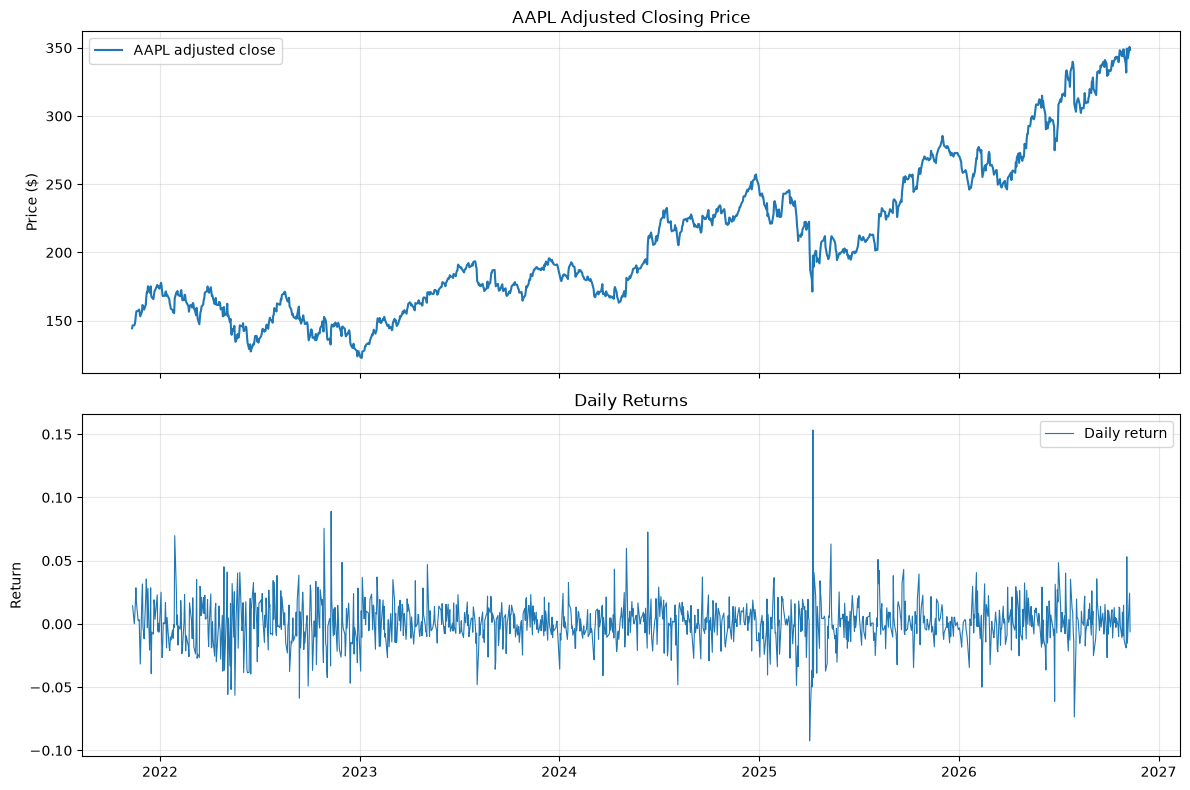

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

axes[0].plot(data.index, data["Close"], label=f"{ticker} adjusted close")
axes[0].set_title(f"{ticker} Adjusted Closing Price")
axes[0].set_ylabel("Price ($)")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(data.index, data["Daily_Return"], label="Daily return", linewidth=0.8)
axes[1].set_title("Daily Returns")
axes[1].set_ylabel("Return")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()


## 3. Risk and return metrics

In [4]:
risk_free_rate = 0.04
asset_metrics = summarize_returns(data["Daily_Return"], risk_free_rate=risk_free_rate)
pd.Series(asset_metrics, name="AAPL").to_frame()


,AAPL
total_return,1.412859
cagr,0.193806
annualized_volatility,0.281626
max_drawdown,-0.333605
sharpe_ratio,0.630081


## 4. Moving-average strategy and backtest

In [5]:
backtest = run_backtest(
    data,
    fast_window=20,
    slow_window=50,
    transaction_cost=0.001,
    train_fraction=0.70,
    risk_free_rate=risk_free_rate,
)

results = backtest["results"]
test = backtest["test"]

print(f"Out-of-sample start date: {backtest['split_date'].date()}")
print(f"Training observations: {len(backtest['train']):,}")
print(f"Test observations: {len(test):,}")


Out-of-sample start date: 2025-05-13
Training observations: 877
Test observations: 377


## 5. Moving averages and signals

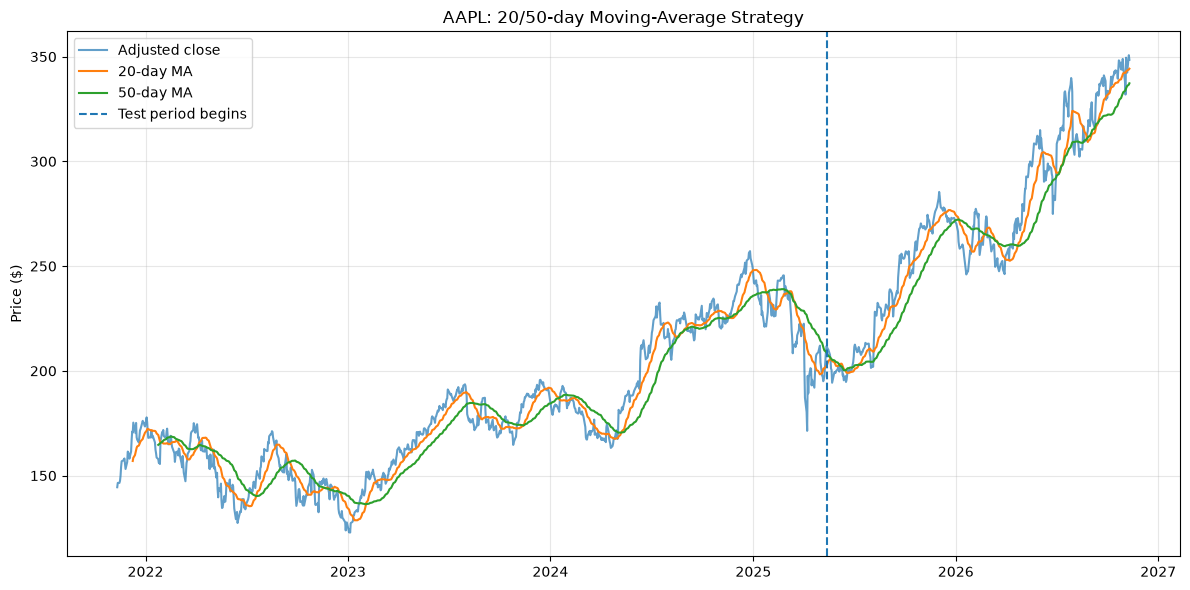

In [6]:
fig, ax = plt.subplots(figsize=(12, 6))
ax.plot(results.index, results["Close"], label="Adjusted close", alpha=0.7)
ax.plot(results.index, results["Fast_MA"], label="20-day MA")
ax.plot(results.index, results["Slow_MA"], label="50-day MA")
ax.axvline(backtest["split_date"], linestyle="--", label="Test period begins")
ax.set_title(f"{ticker}: 20/50-day Moving-Average Strategy")
ax.set_ylabel("Price ($)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 6. Full-period strategy versus buy-and-hold

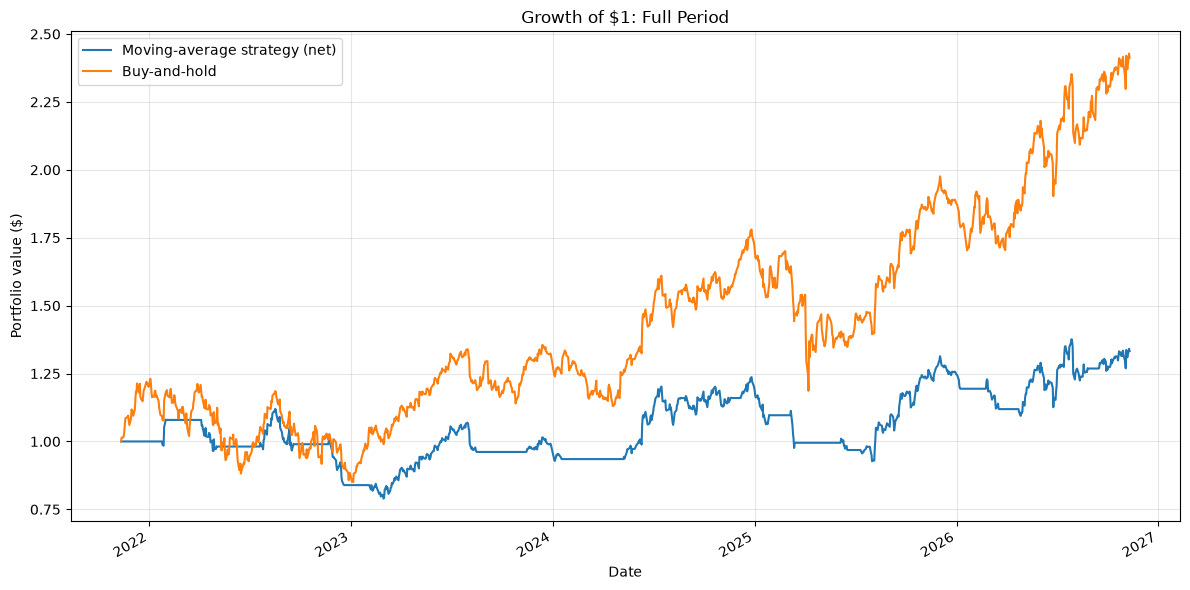

In [7]:
full_growth = pd.DataFrame({
    "Moving-average strategy (net)": (1 + results["Strategy_Net_Return"].fillna(0)).cumprod(),
    "Buy-and-hold": (1 + results["Buy_Hold_Return"].fillna(0)).cumprod(),
})

ax = full_growth.plot(figsize=(12, 6), title="Growth of $1: Full Period")
ax.set_ylabel("Portfolio value ($)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 7. Out-of-sample performance

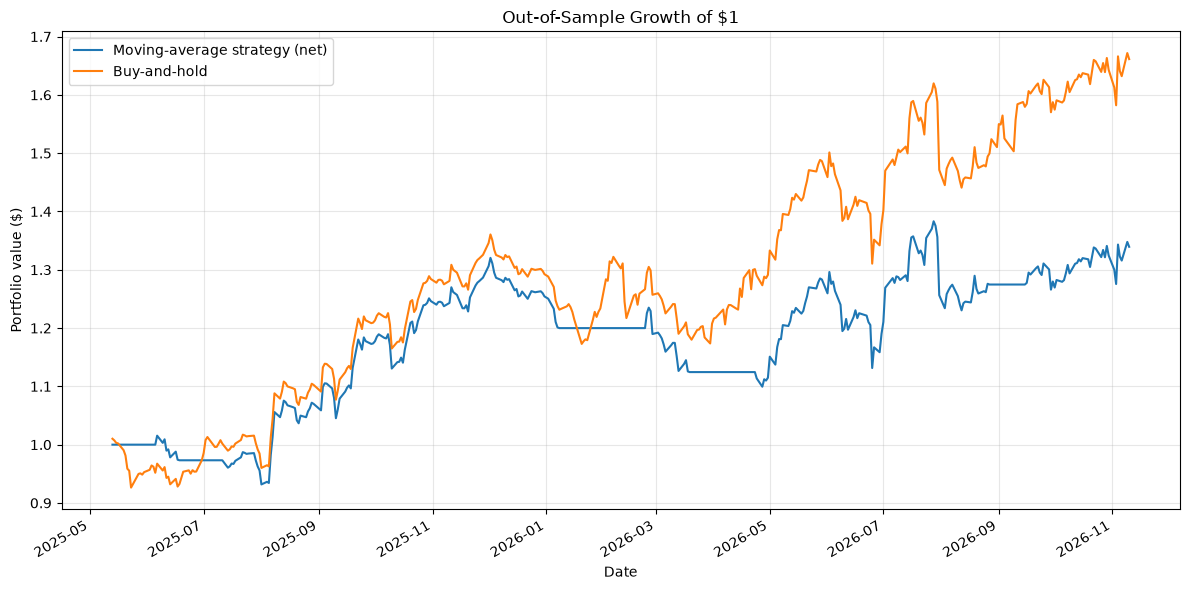

,Strategy (net),Buy-and-hold
total_return,0.339399,0.661342
cagr,0.215713,0.403986
annualized_volatility,0.207071,0.241710
max_drawdown,-0.167366,-0.137985
sharpe_ratio,0.857485,1.363019


In [8]:
test_growth = pd.DataFrame({
    "Moving-average strategy (net)": (1 + test["Strategy_Net_Return"].fillna(0)).cumprod(),
    "Buy-and-hold": (1 + test["Buy_Hold_Return"].fillna(0)).cumprod(),
})

ax = test_growth.plot(figsize=(12, 6), title="Out-of-Sample Growth of $1")
ax.set_ylabel("Portfolio value ($)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

test_metrics = pd.DataFrame({
    "Strategy (net)": backtest["metrics"]["test_strategy"],
    "Buy-and-hold": backtest["metrics"]["test_buy_and_hold"],
})
display(test_metrics)


## 8. Drawdown comparison

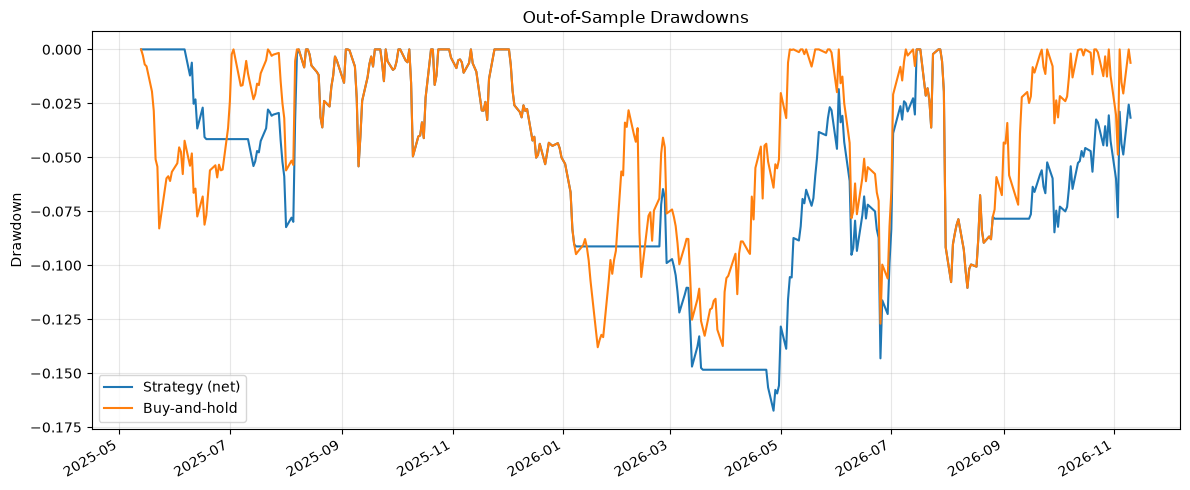

In [9]:
def drawdown_from_returns(returns):
    wealth = (1 + returns.fillna(0)).cumprod()
    wealth = pd.concat([pd.Series([1.0], index=[wealth.index[0] - pd.Timedelta(nanoseconds=1)]), wealth])
    return wealth / wealth.cummax() - 1

drawdowns = pd.DataFrame({
    "Strategy (net)": drawdown_from_returns(test["Strategy_Net_Return"]),
    "Buy-and-hold": drawdown_from_returns(test["Buy_Hold_Return"]),
})
drawdowns.plot(figsize=(12, 5), title="Out-of-Sample Drawdowns")
plt.ylabel("Drawdown")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 9. Interpretation
Compare the strategy and benchmark over identical test dates. Consider total return, CAGR, volatility, maximum drawdown, and Sharpe ratio together. The results are specific to AAPL, the selected period, and the chosen strategy settings; they are not evidence of general profitability.